Candidates after thresholding: 295
Final detections: 49


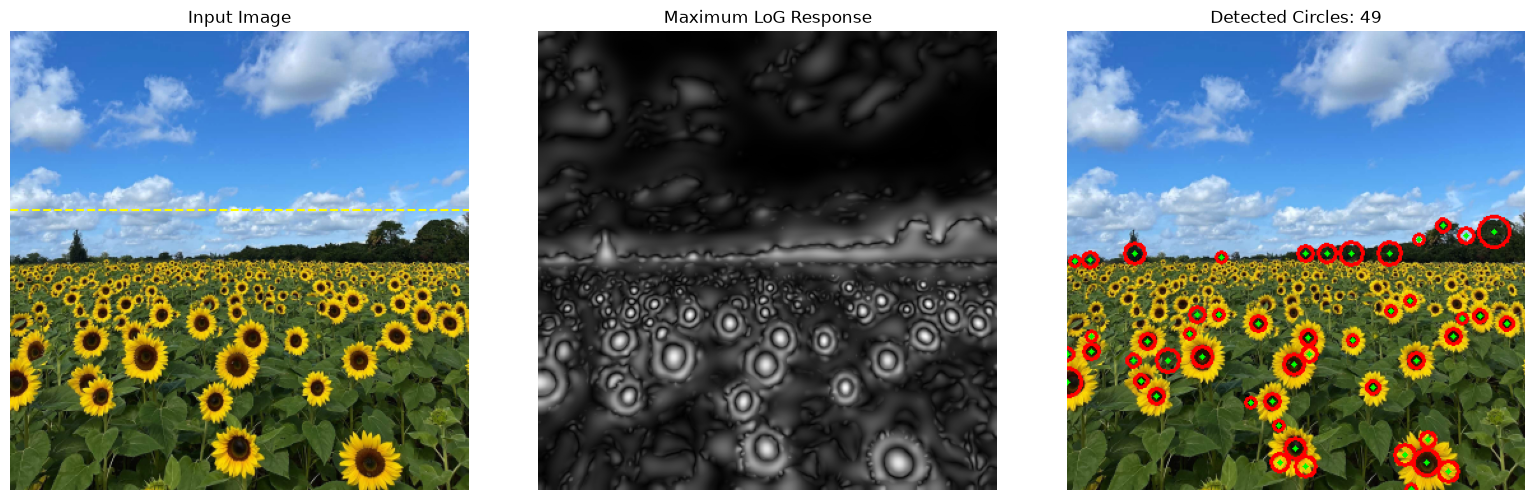


10 largest detected circles:
1. Center=(335, 157), Radius=12.02 px, Sigma=8.5, Response=211.35
2. Center=(0, 275), Radius=10.61 px, Sigma=7.5, Response=351.02
3. Center=(282, 338), Radius=9.90 px, Sigma=7.0, Response=355.18
4. Center=(223, 174), Radius=9.19 px, Sigma=6.5, Response=256.84
5. Center=(253, 174), Radius=9.19 px, Sigma=6.5, Response=244.78
6. Center=(79, 258), Radius=9.19 px, Sigma=6.5, Response=181.21
7. Center=(106, 255), Radius=8.49 px, Sigma=6.0, Response=369.22
8. Center=(179, 327), Radius=8.49 px, Sigma=6.0, Response=351.10
9. Center=(178, 261), Radius=7.78 px, Sigma=5.5, Response=357.78
10. Center=(53, 174), Radius=7.78 px, Sigma=5.5, Response=306.53


In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Step 1: Load and resize the image
image_path = r"E:\SEM 5\vision\Assignment 02\EN3160_Assignment_02\a2images\the_berry_farms_sunflower_field.jpeg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

im_reduced = cv2.resize(
    image_rgb, (360, 360),
    interpolation=cv2.INTER_AREA
)

gray = cv2.cvtColor(
    im_reduced, cv2.COLOR_RGB2GRAY
).astype(np.float32)

# Step 2: Set parameters
sigmas = np.arange(2.0, 9.0, 0.5)
threshold = 180.0
horizon_y = 140
minimum_sigma = 3.0

# Step 3: Generate scale-space LoG responses
responses = []

for sigma in sigmas:
    blurred = cv2.GaussianBlur(
        gray, (0, 0),
        sigmaX=float(sigma),
        sigmaY=float(sigma)
    )

    laplacian = cv2.Laplacian(
        blurred, cv2.CV_32F, ksize=3
    )

    response = np.abs((sigma ** 2) * laplacian)
    responses.append(response)

responses = np.stack(responses, axis=0)

# Step 4: Find local maxima in space and scale
local_max = maximum_filter(
    responses,
    size=(3, 3, 3),
    mode="nearest"
)

is_local_max = (
    (responses == local_max) &
    (responses >= threshold)
)

scale_idx, y_coords, x_coords = np.where(is_local_max)

strengths = responses[
    scale_idx, y_coords, x_coords
]

print("Candidates after thresholding:", len(strengths))

# Step 5: Restrict detections to the sunflower field
field_mask = (
    (y_coords > horizon_y) &
    (sigmas[scale_idx] >= minimum_sigma)
)

scale_idx = scale_idx[field_mask]
y_coords = y_coords[field_mask]
x_coords = x_coords[field_mask]
strengths = strengths[field_mask]

# Step 6: Estimate circle radii
radii = np.sqrt(2.0) * sigmas[scale_idx]

# Step 7: Sort candidates by response strength
order = np.argsort(strengths)[::-1]
accepted = []

# Step 8: Suppress duplicate detections
minimum_distance = 12.0

for i in order:
    candidate = {
        "x": int(x_coords[i]),
        "y": int(y_coords[i]),
        "radius": float(radii[i]),
        "sigma": float(sigmas[scale_idx[i]]),
        "strength": float(strengths[i])
    }

    duplicate = False

    for previous in accepted:
        dx = candidate["x"] - previous["x"]
        dy = candidate["y"] - previous["y"]
        distance = np.hypot(dx, dy)

        suppression_distance = max(
            minimum_distance,
            1.8 * max(
                candidate["radius"],
                previous["radius"]
            )
        )

        if distance < suppression_distance:
            duplicate = True
            break

    if not duplicate:
        accepted.append(candidate)

print("Final detections:", len(accepted))

# Step 9: Draw circles
result = im_reduced.copy()

for detection in accepted:
    x = detection["x"]
    y = detection["y"]
    radius = max(3, int(round(detection["radius"])))

    cv2.circle(
        result, (x, y), radius,
        (255, 0, 0), 2
    )

    cv2.circle(
        result, (x, y), 2,
        (0, 255, 0), -1
    )

# Step 10: Display results
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(im_reduced)
axes[0].axhline(
    horizon_y, color="yellow", linestyle="--"
)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(
    np.max(responses, axis=0), cmap="gray"
)
axes[1].set_title("Maximum LoG Response")
axes[1].axis("off")

axes[2].imshow(result)
axes[2].set_title(f"Detected Circles: {len(accepted)}")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Step 11: Report the largest detected circles
largest_circles = sorted(
    accepted,
    key=lambda item: item["radius"],
    reverse=True
)[:10]

print("\n10 largest detected circles:")

for i, detection in enumerate(largest_circles, 1):
    print(
        f"{i}. Center=({detection['x']}, {detection['y']}), "
        f"Radius={detection['radius']:.2f} px, "
        f"Sigma={detection['sigma']:.1f}, "
        f"Response={detection['strength']:.2f}"
    )


## Question 1: Sunflower Detection Using Laplacian of Gaussian

The sunflower field image was converted to grayscale and processed using the Laplacian of Gaussian (LoG) method at multiple scales. Local maxima in the scale-space were identified as potential sunflower heads. A response threshold and duplicate suppression were applied to reduce false detections and overlapping circles.

The sigma values ranged from **2.0 to 8.5 pixels**, with an increment of **0.5 pixels**. The radius of each detected blob was estimated using

$$
r \approx \sqrt{2}\sigma
$$

Not all sunflower heads were detected because some flowers overlap, have low contrast, or produce weak LoG responses. The detection results depend on the selected threshold, sigma range, and duplicate suppression settings.

The detected circles were drawn in red, with green dots marking their centres. The parameters of the largest detected circles, including their centre coordinates, radius, and corresponding sigma values, were obtained from the program. The `cv2.HoughCircles()` function was not used.